# Music Genre Classification

## 1. Import libraries & load dataset

In [54]:
from tqdm import tqdm
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
import librosa
import librosa.display

### 1.1 Vérifier que le dataset est complet

Chaque genre doit contenir **exactement 100 fichiers** (1000 au total).

In [56]:
counts = {}
for genre in sorted(os.listdir(DATA_PATH)):
    genre_dir = os.path.join(DATA_PATH, genre)
    if os.path.isdir(genre_dir):
        counts[genre] = len([f for f in os.listdir(genre_dir) if f.endswith(".wav")])

for genre, n in counts.items():
    print(f"{genre:10s} : {n} fichiers")
print("\nTotal :", sum(counts.values()))

blues      : 100 fichiers
classical  : 100 fichiers
country    : 100 fichiers
disco      : 100 fichiers
hiphop     : 100 fichiers
jazz       : 100 fichiers
metal      : 100 fichiers
pop        : 100 fichiers
reggae     : 100 fichiers
rock       : 100 fichiers

Total : 1000


### 1.5 Repérer les fichiers corrompus

Dans Kaggle, `jazz.00054.wav` est connu pour être **corrompu**. On va tenter de charger 1 seconde de chaque fichier et on liste ceux qui échouent (1 à 2 minutes).

In [5]:
bad_files = []
for genre in counts:
    for f in os.listdir(os.path.join(DATA_PATH, genre)):
        path = os.path.join(DATA_PATH, genre, f)
        try:
            librosa.load(path, sr=22050, duration=1)
        except Exception:
            bad_files.append(path)

print("Fichiers illisibles :", bad_files)

Fichiers illisibles : ['data/genres_original/jazz/jazz.00054.wav']


### 1.6 Visualiser un signal audio
On doit voir environ 30 s à 22050 Hz (défaut de librosa). La forme d'onde représente l'amplitude dans le temps : c'est la matière première de l'étape 2.

Durée : 30.0 s | Fréquence d'échantillonnage : 22050 Hz


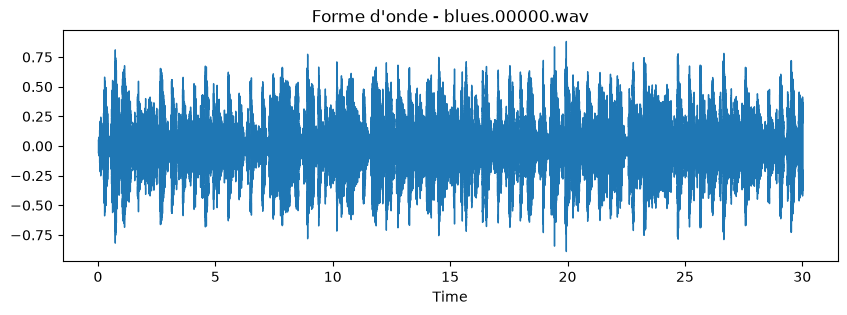

In [ ]:
y, sr = librosa.load(f"data/genres_original/blues/blues.00000.wav")
print(f"Durée : {len(y)/sr:.1f} s | Fréquence d'échantillonnage : {sr} Hz")

plt.figure(figsize=(10, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Forme d'onde - blues.00000.wav")
plt.show()

## 2. Feature extraction

Chaque morceau de 30 s est découpé en **10 segments de 3 s**, et chaque segment devient une ligne du dataset (~10 000 lignes).

### 2.1 Constante
Un segment de 3 s = 66 150 échantillons. `HOP_LENGTH` est le pas de la fenêtre d'analyse.

In [60]:
from tqdm import tqdm

SAMPLE_RATE = 22050
TRACK_DURATION = 30
NUM_SEGMENTS = 10
N_MFCC = 13
HOP_LENGTH = 512

SAMPLES_PER_TRACK = SAMPLE_RATE * TRACK_DURATION
SAMPLES_PER_SEGMENT = SAMPLES_PER_TRACK // NUM_SEGMENTS
print("Échantillons par segment :", SAMPLES_PER_SEGMENT)

Échantillons par segment : 66150


### 2.2 Fonction d'extraction (MFCC, Chroma, Centroid, Rolloff, ZCR)

Les features librosa sont des matrices (coefficients × temps). On les résume par leur **moyenne** (niveau typique) et leur **écart-type** (variabilité).

- **MFCC (13)** : timbre.
- **Chroma (12)** : harmonie (12 notes).
- **Spectral Centroid** : brillance.
- **Spectral Rolloff** : fréquence sous laquelle se trouve 85 % de l'énergie.
- **Zero-Crossing Rate** : bruit / percussion.

Total : **56 features**.

In [57]:
def extract_features(segment, sr=SAMPLE_RATE):
    """Calcule les features d'un segment audio et renvoie un dictionnaire."""
    feats = {}

    mfcc = librosa.feature.mfcc(y=segment, sr=sr, n_mfcc=N_MFCC, hop_length=HOP_LENGTH)
    for i in range(N_MFCC):
        feats[f"mfcc{i+1}_mean"] = np.mean(mfcc[i])
        feats[f"mfcc{i+1}_std"] = np.std(mfcc[i])

    chroma = librosa.feature.chroma_stft(y=segment, sr=sr, hop_length=HOP_LENGTH)
    for i in range(chroma.shape[0]):
        feats[f"chroma{i+1}_mean"] = np.mean(chroma[i])
        feats[f"chroma{i+1}_std"] = np.std(chroma[i])

    centroid = librosa.feature.spectral_centroid(y=segment, sr=sr, hop_length=HOP_LENGTH)
    feats["spectral_centroid_mean"] = np.mean(centroid)
    feats["spectral_centroid_std"] = np.std(centroid)

    rolloff = librosa.feature.spectral_rolloff(y=segment, sr=sr, hop_length=HOP_LENGTH)
    feats["spectral_rolloff_mean"] = np.mean(rolloff)
    feats["spectral_rolloff_std"] = np.std(rolloff)

    zcr = librosa.feature.zero_crossing_rate(segment, hop_length=HOP_LENGTH)
    feats["zcr_mean"] = np.mean(zcr)
    feats["zcr_std"] = np.std(zcr)

    return feats

### 2.3 Test rapide sur un segment

On vérifie que la fonction renvoie bien **56 valeurs** avant de lancer la boucle complète.

In [58]:
y, sr = librosa.load(f"{DATA_PATH}/blues/blues.00000.wav", sr=SAMPLE_RATE)
test = extract_features(y[:SAMPLES_PER_SEGMENT])
print("Nombre de features :", len(test)) 
print(list(test.items())[:5])

Nombre de features : 56
[('mfcc1_mean', np.float32(-119.01805)), ('mfcc1_std', np.float32(49.944424)), ('mfcc2_mean', np.float32(125.08036)), ('mfcc2_std', np.float32(16.189907)), ('mfcc3_mean', np.float32(-23.394333))]


### 2.4 Boucle principale : genre → fichier → segment

Pour chaque segment on construit un dictionnaire (features + `genre` + `track_id` + `segment`) ajouté à la liste maître `all_data`. Les fichiers corrompus sont ignorés par `try/except`.

In [61]:
all_data = []
skipped = []

genres = sorted([g for g in os.listdir(DATA_PATH)
                 if os.path.isdir(os.path.join(DATA_PATH, g))])

for genre in genres:
    genre_dir = os.path.join(DATA_PATH, genre)
    files = sorted([f for f in os.listdir(genre_dir) if f.endswith(".wav")])

    for fname in tqdm(files, desc=genre):
        path = os.path.join(genre_dir, fname)

        try:
            y, sr = librosa.load(path, sr=SAMPLE_RATE)
        except Exception:
            skipped.append((fname, "illisible"))
            continue

        if len(y) < SAMPLES_PER_TRACK:
            skipped.append((fname, "trop court"))
            continue

        for s in range(NUM_SEGMENTS):
            start = s * SAMPLES_PER_SEGMENT
            segment = y[start:start + SAMPLES_PER_SEGMENT]

            feats = extract_features(segment, sr)
            feats["genre"] = genre
            feats["track_id"] = fname
            feats["segment"] = s
            all_data.append(feats)

print("\nSegments extraits :", len(all_data))   # attendu : ~9 990
print("Fichiers ignorés  :", skipped)

rock: 100%|██████████| 100/100 [00:31<00:00,  3.22it/s]


Segments extraits : 9900
Fichiers ignorés  : [('classical.00049.wav', 'trop court'), ('classical.00051.wav', 'trop court'), ('country.00003.wav', 'trop court'), ('country.00004.wav', 'trop court'), ('country.00007.wav', 'trop court'), ('disco.00014.wav', 'trop court'), ('hiphop.00031.wav', 'trop court'), ('hiphop.00032.wav', 'trop court'), ('jazz.00054.wav', 'illisible'), ('rock.00038.wav', 'trop court')]


### 2.5 DataFrame et sauvegarde en CSV

On a 59 colonnes, soit 56 features + `genre` + `track_id` + `segment`. On sauvegarde pour **ne jamais refaire l'extraction**.

In [16]:
df = pd.DataFrame(all_data)
print("Forme du DataFrame :", df.shape)
print(df["genre"].value_counts())
df.head()

Forme du DataFrame : (9900, 59)
genre
blues        1000
metal        1000
pop          1000
reggae       1000
disco         990
jazz          990
rock          990
classical     980
hiphop        980
country       970
Name: count, dtype: int64


,mfcc1_mean,mfcc1_std,mfcc2_mean,mfcc2_std,mfcc3_mean,mfcc3_std,mfcc4_mean,mfcc4_std,mfcc5_mean,mfcc5_std,...,chroma12_std,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,zcr_mean,zcr_std,genre,track_id,segment
0,-119.018051,49.944424,125.080360,16.189907,-23.394333,19.115284,41.321732,13.487514,-5.931893,12.348084,...,0.282362,1773.357910,411.644043,3714.063477,1040.759155,0.081851,0.023615,blues,blues.00000.wav,0
1,-125.977165,45.241447,122.374199,14.780329,-20.679749,15.271172,50.035046,11.995066,-11.250690,11.821546,...,0.318054,1817.244019,301.274475,3870.510498,819.837280,0.087173,0.032088,blues,blues.00000.wav,1
2,-132.618149,61.601986,114.815521,15.709211,-14.718565,13.891207,50.017944,12.392982,-0.424875,11.081537,...,0.230604,1790.722412,331.769806,4000.206787,886.538269,0.071383,0.020622,blues,blues.00000.wav,2
3,-118.325325,50.058483,131.587173,17.984241,-18.493637,10.475515,39.478863,13.966427,-12.992120,11.854437,...,0.301698,1660.545166,330.903229,3579.149414,950.407654,0.069426,0.017435,blues,blues.00000.wav,3
4,-106.182121,46.093067,134.275955,14.477101,-19.761967,13.183636,39.920498,10.551027,-14.074065,9.995866,...,0.274020,1634.464966,278.254242,3480.097168,767.413208,0.070102,0.016984,blues,blues.00000.wav,4


In [ ]:
df.to_csv("/cleaned/features.csv", index=False)

check = pd.read_csv("cleaned/features.csv")
print("Relu :", check.shape)
print("Valeurs manquantes :", check.isna().sum().sum())

Relu : (9900, 59)
Valeurs manquantes : 0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Data exploration

In [ ]:
df = pd.read_csv("cleaned/features.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9900 entries, 0 to 9899
Data columns (total 59 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   mfcc1_mean              9900 non-null   float64
 1   mfcc1_std               9900 non-null   float64
 2   mfcc2_mean              9900 non-null   float64
 3   mfcc2_std               9900 non-null   float64
 4   mfcc3_mean              9900 non-null   float64
 5   mfcc3_std               9900 non-null   float64
 6   mfcc4_mean              9900 non-null   float64
 7   mfcc4_std               9900 non-null   float64
 8   mfcc5_mean              9900 non-null   float64
 9   mfcc5_std               9900 non-null   float64
 10  mfcc6_mean              9900 non-null   float64
 11  mfcc6_std               9900 non-null   float64
 12  mfcc7_mean              9900 non-null   float64
 13  mfcc7_std               9900 non-null   float64
 14  mfcc8_mean              9900 non-null   float64
 15

In [22]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mfcc1_mean,9900.0,-146.238697,106.252463,-661.934630,-202.290003,-120.841887,-70.875818,107.516060
mfcc1_std,9900.0,48.882448,20.741424,4.968486,34.017040,46.063072,60.865335,211.939540
mfcc2_mean,9900.0,101.017964,34.542749,-12.043992,76.324921,98.673610,122.344217,249.630050
mfcc2_std,9900.0,22.716650,8.445919,3.018512,16.429971,21.515441,27.723167,71.160560
mfcc3_mean,9900.0,-9.975215,23.967752,-103.846030,-26.888023,-11.679203,6.033028,80.177570
mfcc3_std,9900.0,18.162323,6.735405,1.420238,13.278414,17.290949,22.096672,64.457634
mfcc4_mean,9900.0,37.245225,17.777235,-35.187386,24.491849,37.914492,49.833851,89.275080
mfcc4_std,9900.0,12.854989,4.459121,1.942247,9.496239,12.343670,15.582518,47.916912
mfcc5_mean,9900.0,-2.062113,13.537549,-47.956093,-11.897472,-1.664712,7.938492,46.826180
mfcc5_std,9900.0,11.310105,4.040845,3.172092,8.279208,10.725424,13.749092,39.407460


In [24]:
missing = df.isna().sum()
print("Valeurs manquantes (>0) :")
print(missing[missing > 0])
print("Total :", missing.sum())

if missing.sum() > 0:
    df = df.dropna().reset_index(drop=True)
    print("Lignes restantes :", len(df))

Valeurs manquantes (>0) :
Series([], dtype: int64)
Total : 0


### 3.2 Data Visualisation

#### 3.2.1 Countplot

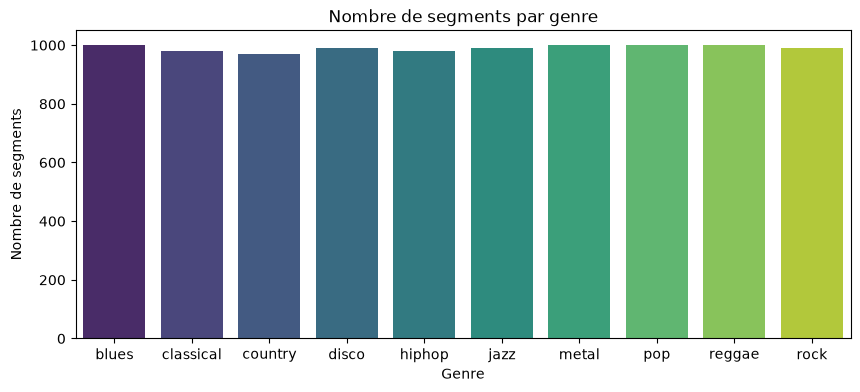

In [25]:
order = sorted(df["genre"].unique())

plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="genre", order=order, hue="genre", palette="viridis", legend=False)
plt.title("Nombre de segments par genre")
plt.xlabel("Genre")
plt.ylabel("Nombre de segments")
plt.show()

### 3.2.2 Box plot

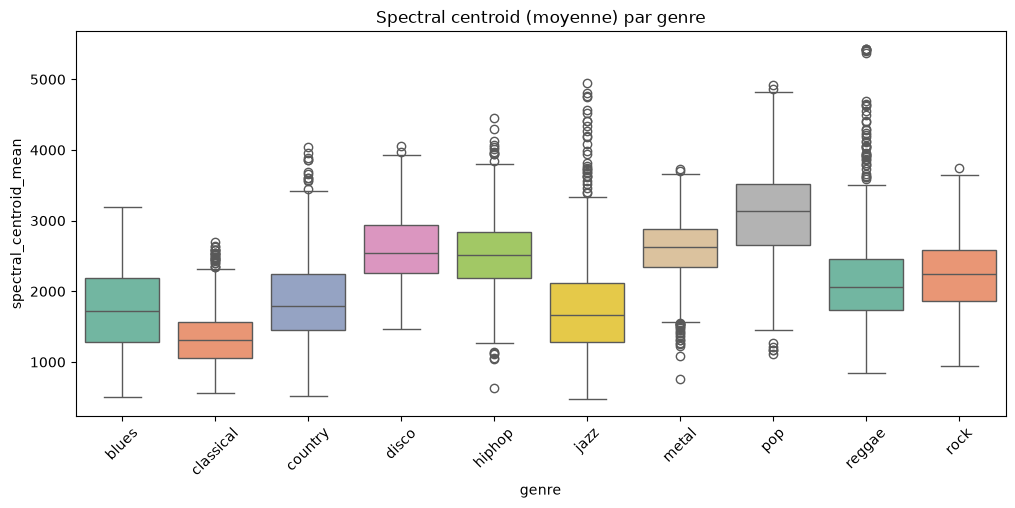

In [26]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="genre", y="spectral_centroid_mean", order=order,
            hue="genre", palette="Set2", legend=False)
plt.title("Spectral centroid (moyenne) par genre")
plt.xticks(rotation=45)
plt.show()

### 3.2.3 Violin plot

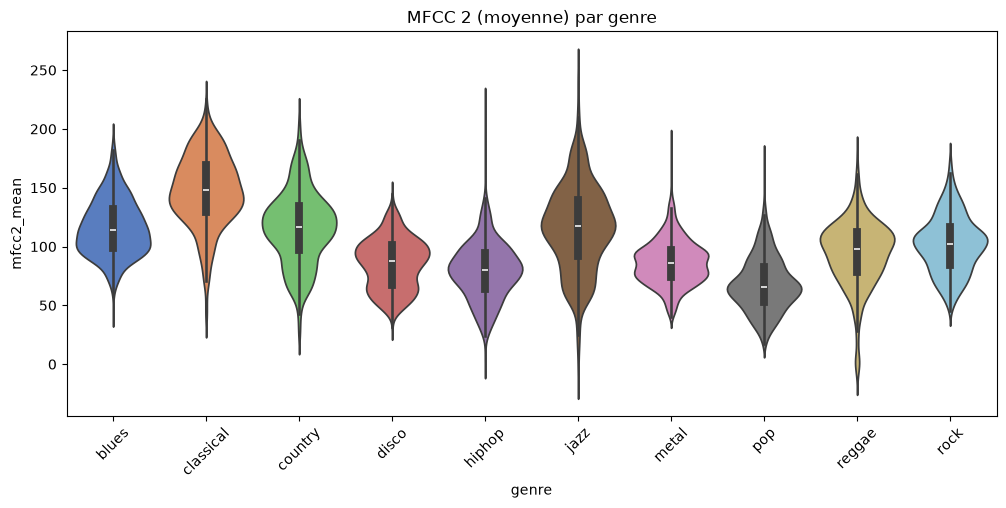

In [27]:
plt.figure(figsize=(12, 5))
sns.violinplot(data=df, x="genre", y="mfcc2_mean", order=order,
               hue="genre", palette="muted", legend=False)
plt.title("MFCC 2 (moyenne) par genre")
plt.xticks(rotation=45)
plt.show()

### 3.2.5 Matrice de corrélation et heatmap

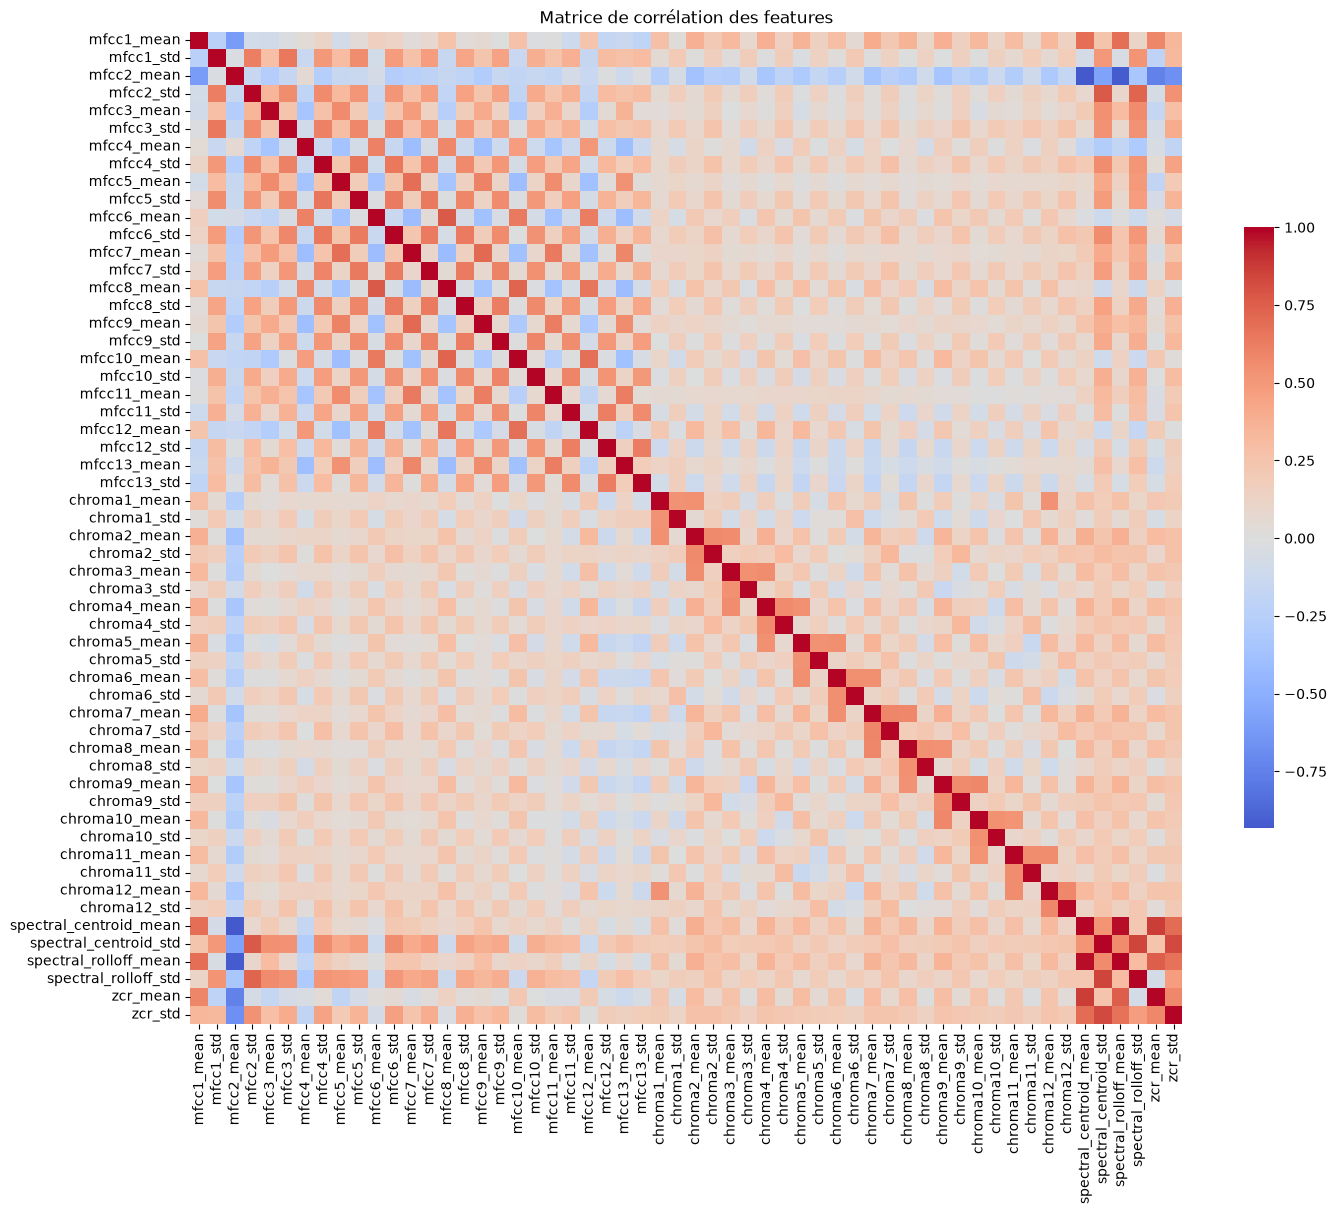

In [28]:
feature_cols = [c for c in df.columns if c not in ["genre", "track_id", "segment"]]
corr = df[feature_cols].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Matrice de corrélation des features")
plt.show()

## 4. Training baseline models

### 4.1 Séparer X et y, encoder les labels

In [30]:
import joblib
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = df[feature_cols].values
groups = df["track_id"].astype(str).values

le = LabelEncoder()
y = le.fit_transform(df["genre"])
print(dict(zip(le.classes_, range(len(le.classes_)))))

{'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}


### 4.2 Split train / test

In [31]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train = groups[train_idx]

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Morceaux communs :", len(set(groups[train_idx]) & set(groups[test_idx])))  # attendu : 0

Train : (7920, 56) | Test : (1980, 56)
Morceaux communs : 0


### 4.3 Standardisation

In [32]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Moyenne train (≈0) :", X_train_s.mean().round(3), "| Écart-type (≈1) :", X_train_s.std().round(3))

Moyenne train (≈0) : -0.0 | Écart-type (≈1) : 1.0


### 4.4 Entraîner Logistic Regression, SVM et Random Forest

In [33]:
logreg = LogisticRegression(max_iter=2000, random_state=42)
logreg.fit(X_train_s, y_train)

svm = SVC(kernel="rbf", C=10, probability=True, random_state=42)
svm.fit(X_train_s, y_train)

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train_s, y_train)

/home/avande/music_genre_classification/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

### 4.5 Accuracy de chaque modèle

In [34]:
baseline_models = {"Logistic Regression": logreg, "SVM": svm, "Random Forest": rf}

for name, model_ in baseline_models.items():
    acc = accuracy_score(y_test, model_.predict(X_test_s))
    print(f"{name:20s} accuracy : {acc:.3f}")

Logistic Regression  accuracy : 0.571
SVM                  accuracy : 0.636
Random Forest        accuracy : 0.598


### 4.6 Sauvegarde

In [35]:
os.makedirs("models", exist_ok=True)

joblib.dump(logreg, "models/logreg.pkl")
joblib.dump(svm, "models/svm.pkl")
joblib.dump(rf, "models/rf.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le, "models/label_encoder.pkl")
joblib.dump(feature_cols, "models/feature_cols.pkl")

np.savez("models/data_split.npz",
         X_train_s=X_train_s, X_test_s=X_test_s,
         y_train=y_train, y_test=y_test,
         groups_train=groups_train)
print("Sauvegarde terminée :", os.listdir("models"))

Sauvegarde terminée : ['feature_cols.pkl', 'data_split.npz', 'svm.pkl', 'scaler.pkl', 'label_encoder.pkl', 'rf.pkl', 'logreg.pkl']


## 5. Neural network (CNN 1D)

### 5.1 Mise en forme des données

`Conv1D` attend `(échantillons, longueur, canaux)`, soit `(N, 56, 1)`. Le `validation_split` de Keras prendrait les dernières lignes sans mélanger (données triées par genre), donc on crée la validation **par morceau**.

In [37]:
d = np.load("models/data_split.npz", allow_pickle=True)
X_train_s, X_test_s = d["X_train_s"], d["X_test_s"]
y_train, y_test = d["y_train"], d["y_test"]
groups_train = d["groups_train"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr_idx, val_idx = next(gss.split(X_train_s, y_train, groups_train))

X_tr = X_train_s[tr_idx][..., np.newaxis]
X_val = X_train_s[val_idx][..., np.newaxis]
X_te = X_test_s[..., np.newaxis]
y_tr, y_val = y_train[tr_idx], y_train[val_idx]

print("Train :", X_tr.shape, "| Val :", X_val.shape, "| Test :", X_te.shape)

Train : (6730, 56, 1) | Val : (1190, 56, 1) | Test : (1980, 56, 1)


### 5.2 Architecture

In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, BatchNormalization,
                                     Flatten, Dense, Dropout)

n_features = X_tr.shape[1]
n_classes = len(np.unique(y_train))

model = Sequential([
    Input(shape=(n_features, 1)),

    Conv1D(64, kernel_size=3, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),
    BatchNormalization(),

    Conv1D(128, kernel_size=3, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),
    BatchNormalization(),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(n_classes, activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 56, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 28, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 28, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 14, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1792)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       229,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 256,522 (1002.04 KB)

 Trainable params: 256,138 (1000.54 KB)

 Non-trainable params: 384 (1.50 KB)

### 5.3 Entraînement

In [41]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(X_tr, y_tr,
                    validation_data=(X_val, y_val),
                    epochs=100,
                    batch_size=32,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5496 - loss: 1.3922 - val_accuracy: 0.2807 - val_loss: 2.1011
Epoch 2/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7143 - loss: 0.8305 - val_accuracy: 0.5252 - val_loss: 1.3379
Epoch 3/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7863 - loss: 0.6340 - val_accuracy: 0.6176 - val_loss: 1.2074
Epoch 4/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8248 - loss: 0.4938 - val_accuracy: 0.6193 - val_loss: 1.3279
Epoch 5/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8581 - loss: 0.4091 - val_accuracy: 0.6101 - val_loss: 1.4252
Epoch 6/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8774 - loss: 0.3504 - val_accuracy: 0.6286 - val_loss: 1.3958
Epoch 7/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8966 - loss: 0.3132 - val_accuracy: 0.6084 - val_loss: 1.5018
Epoch 8/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9165 - loss: 0.2420 - val_accu

### 5.5 Courbes d'apprentissage

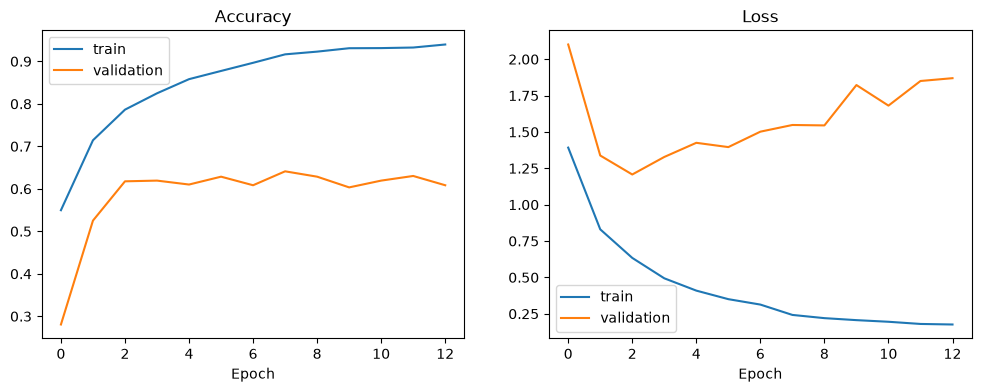

Accuracy test : 0.600


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.show()

test_loss, test_acc = model.evaluate(X_te, y_test, verbose=0)
print(f"Accuracy test : {test_acc:.3f}")

### 5.6 Sauvegarde du modèle

In [44]:
model.save("models/cnn_model.keras")

## 6. Model evaluation & selection

### 6.1 Charger les modèles et prédire

In [45]:
import json
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tensorflow.keras.models import load_model

d = np.load("models/data_split.npz")
X_test_s, y_test = d["X_test_s"], d["y_test"]
le = joblib.load("models/label_encoder.pkl")
class_names = le.classes_

eval_models = {
    "Logistic Regression": joblib.load("models/logreg.pkl"),
    "SVM": joblib.load("models/svm.pkl"),
    "Random Forest": joblib.load("models/rf.pkl"),
}
cnn = load_model("models/cnn_model.h5", compile=False)

preds = {name: m.predict(X_test_s) for name, m in eval_models.items()}
preds["CNN"] = cnn.predict(X_test_s[..., np.newaxis], verbose=0).argmax(axis=1)

### 6.2 Rapports de classification

In [46]:
for name, p in preds.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, p, target_names=class_names, digits=3))


===== Logistic Regression =====
              precision    recall  f1-score   support

       blues      0.555     0.671     0.608       210
   classical      0.665     0.908     0.768       120
     country      0.564     0.400     0.468       220
       disco      0.291     0.242     0.264       190
      hiphop      0.505     0.547     0.525       190
        jazz      0.750     0.639     0.690       230
       metal      0.745     0.811     0.777       180
         pop      0.664     0.783     0.719       230
      reggae      0.482     0.489     0.486       190
        rock      0.414     0.350     0.379       220

    accuracy                          0.571      1980
   macro avg      0.563     0.584     0.568      1980
weighted avg      0.562     0.571     0.562      1980


===== SVM =====
              precision    recall  f1-score   support

       blues      0.640     0.695     0.667       210
   classical      0.680     0.975     0.801       120
     country      0.585     

### 6.3 Matrices de confusion

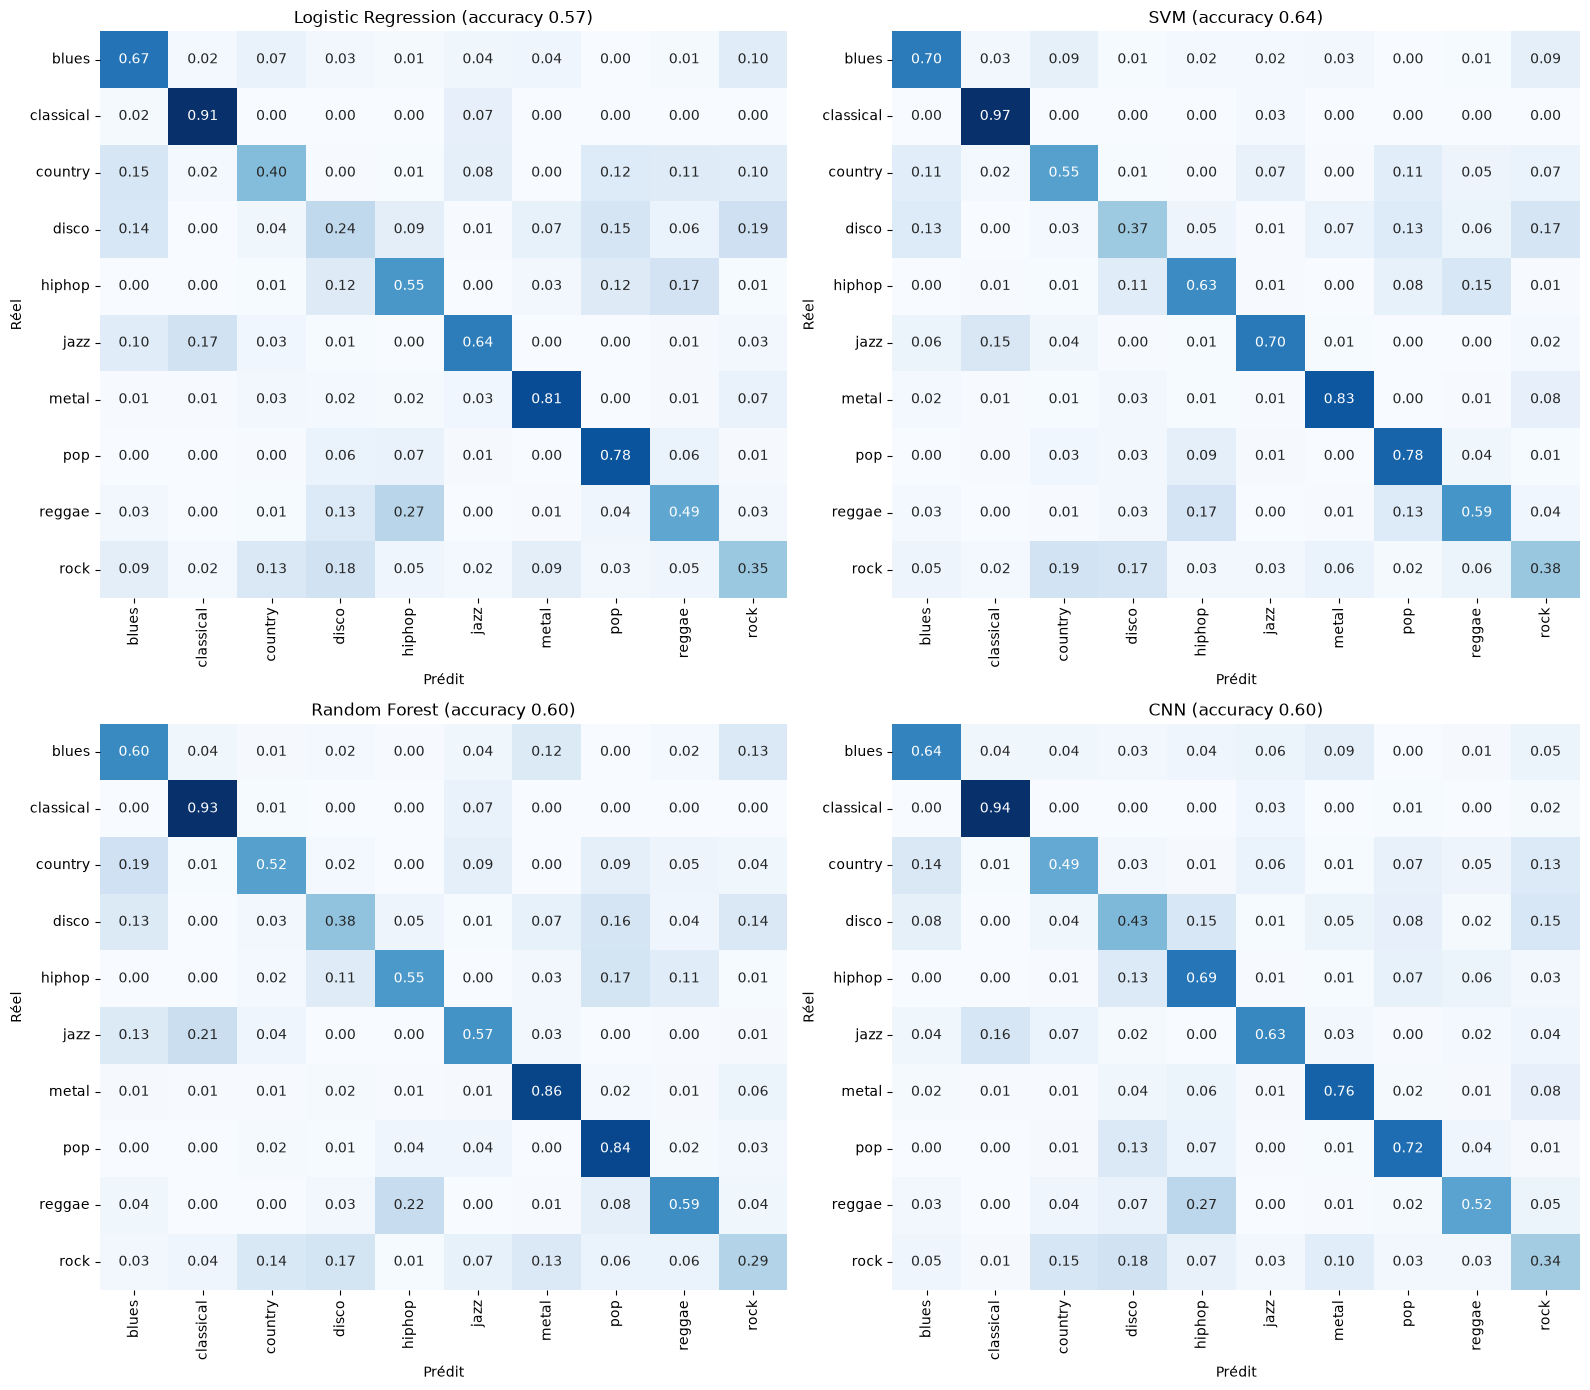

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names,
                cbar=False, ax=ax)
    ax.set_title(f"{name} (accuracy {accuracy_score(y_test, p):.2f})")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")

plt.tight_layout()
plt.show()

### 6.4 Genres les plus confondus

In [48]:
def top_confusions(y_true, y_pred, k=5):
    cm = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm, 0)
    flat = [(cm[i, j], class_names[i], class_names[j])
            for i in range(len(cm)) for j in range(len(cm)) if cm[i, j] > 0]
    return sorted(flat, reverse=True)[:k]

for name, p in preds.items():
    print(f"\n{name} : confusions les plus fréquentes")
    for n, true_g, pred_g in top_confusions(y_test, p):
        print(f"   {true_g:10s} pris pour {pred_g:10s} : {n} segments")


Logistic Regression : confusions les plus fréquentes
   reggae     pris pour hiphop     : 51 segments
   jazz       pris pour classical  : 40 segments
   rock       pris pour disco      : 39 segments
   disco      pris pour rock       : 36 segments
   country    pris pour blues      : 33 segments

SVM : confusions les plus fréquentes
   rock       pris pour country    : 41 segments
   rock       pris pour disco      : 37 segments
   jazz       pris pour classical  : 35 segments
   reggae     pris pour hiphop     : 33 segments
   disco      pris pour rock       : 32 segments

Random Forest : confusions les plus fréquentes
   jazz       pris pour classical  : 49 segments
   reggae     pris pour hiphop     : 42 segments
   country    pris pour blues      : 42 segments
   rock       pris pour disco      : 37 segments
   hiphop     pris pour pop        : 32 segments

CNN : confusions les plus fréquentes
   reggae     pris pour hiphop     : 51 segments
   rock       pris pour disco      : 4

### 6.5 Synthèse et choix du meilleur modèle

On compare sur **accuracy** et **F1 macro**. À performances proches (1-2 points), on choisit le modèle le plus simple.

In [49]:
summary = pd.DataFrame({
    "Accuracy": {n: accuracy_score(y_test, p) for n, p in preds.items()},
    "F1 macro": {n: f1_score(y_test, p, average="macro") for n, p in preds.items()},
}).sort_values("F1 macro", ascending=False).round(3)

display(summary)

best_name = summary.index[0]
print("\nMeilleur modèle :", best_name)

,Accuracy,F1 macro
SVM,0.636,0.636
CNN,0.600,0.605
Random Forest,0.598,0.593
Logistic Regression,0.571,0.568



Meilleur modèle : SVM
